Task 1: Region Segmentation

In [29]:
import numpy as np
import cv2
import matplotlib.pyplot as plt

sar_img = cv2.imread('sar_1.jpg')

sar_gray = cv2.cvtColor(sar_img, cv2.COLOR_BGR2GRAY)

In [30]:
def grow_region(img, start_point, radius=2, threshold=25, method='average'):
    region_mask = np.zeros(img.shape, dtype=np.uint8)
    region_mask[start_point] = 1

    neighborhood = np.ones((2 * radius + 1, 2 * radius + 1), dtype=np.uint8)
    img_float = img.astype(np.float32)

    while True:
        expanded = cv2.dilate(region_mask, neighborhood)
        frontier = (expanded > 0) & (region_mask == 0)

        if not np.any(frontier):
            break

        region_values = img[region_mask > 0]

        if method == 'average':
            reference = region_values.mean()
        elif method == 'mode':
            hist, _ = np.histogram(region_values, bins=256, range=(0, 256))
            reference = float(np.argmax(hist))
        else:
            raise ValueError("Unknown homogeneity criterion")

        accepted = frontier & (
            np.abs(img_float - reference) <= threshold
        )

        if not np.any(accepted):
            break

        region_mask[accepted] = 1

    return region_mask * 255

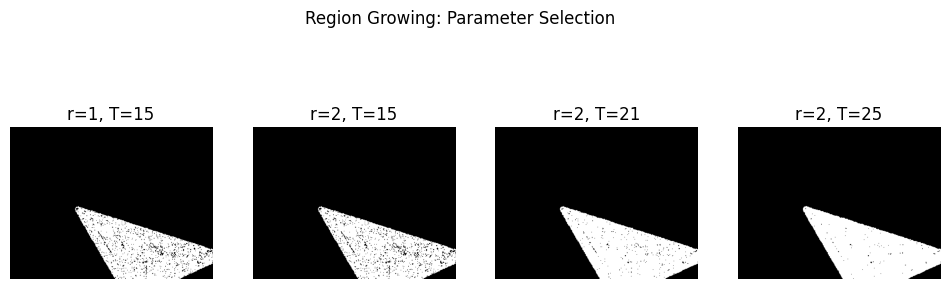

In [31]:
lawn_seed = (200, 200)

experiments = [
    (1, 15),
    (2, 15),
    (2, 21),
    (2, 25)
]

plt.figure(figsize=(12, 4))

for i, (radius_test, thresh_test) in enumerate(experiments):
    test_mask = grow_region(
        sar_gray, lawn_seed,
        radius=radius_test, threshold=thresh_test, method='average'
    )

    plt.subplot(1, 4, i + 1)
    plt.imshow(test_mask, cmap='gray')
    plt.title(f'r={radius_test}, T={thresh_test}')
    plt.axis('off')

plt.suptitle("Region Growing: Parameter Selection")
plt.show()

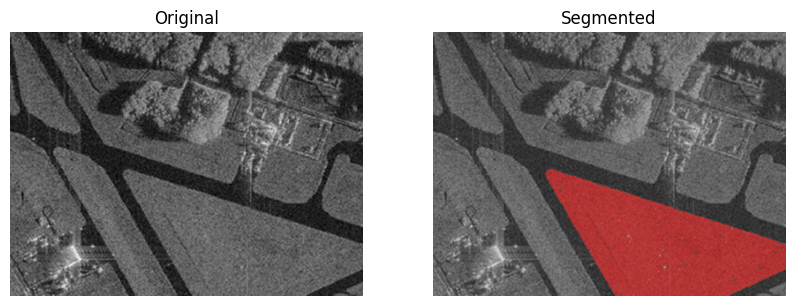

In [32]:
best_r = 2
best_T = 25

mask_average = grow_region(
    sar_gray, lawn_seed,
    radius=best_r, threshold=best_T, method='average'
)

overlay = cv2.cvtColor(sar_gray, cv2.COLOR_GRAY2RGB)
selected = mask_average > 0
overlay[selected] = (
    0.5 * overlay[selected] +
    0.5 * np.array([255, 0, 0])
).astype(np.uint8)

plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(sar_gray, cmap='gray')
plt.title("Original")
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(overlay)
plt.title("Segmented")
plt.axis('off')

plt.show()

Task2: Alternative Homogeneity Criterion - Mode

Homogeneity Criterion Comparison
Region area (mean): 21406 pixels
Region area (mode): 21387 pixels
IoU: 0.9975


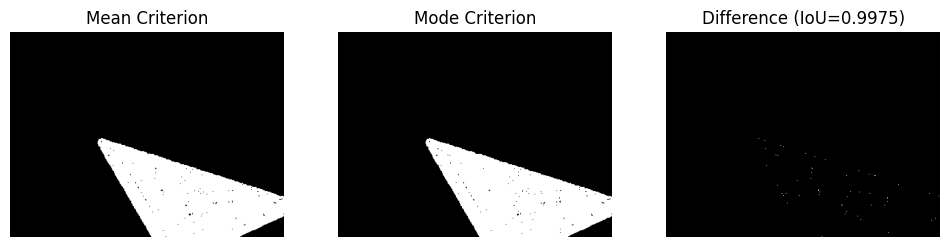

In [33]:
mask_mode = grow_region(
    sar_gray, lawn_seed,
    radius=best_r, threshold=best_T, method='mode'
)

area_avg  = np.count_nonzero(mask_average)
area_mode = np.count_nonzero(mask_mode)

intersection = np.count_nonzero(
    (mask_average > 0) & (mask_mode > 0)
)
union = np.count_nonzero(
    (mask_average > 0) | (mask_mode > 0)
)

iou = intersection / union if union else 0.0
diff = cv2.absdiff(mask_average, mask_mode)

print("Homogeneity Criterion Comparison")
print(f"Region area (mean): {area_avg} pixels")
print(f"Region area (mode): {area_mode} pixels")
print(f"IoU: {iou:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(mask_average, cmap='gray')
plt.title("Mean Criterion")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(mask_mode, cmap='gray')
plt.title("Mode Criterion")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(diff, cmap='gray')
plt.title(f"Difference (IoU={iou:.4f})")
plt.axis('off')

plt.show()

Task 3: Watershed and Distance Transform — Palm Tree Segmentation

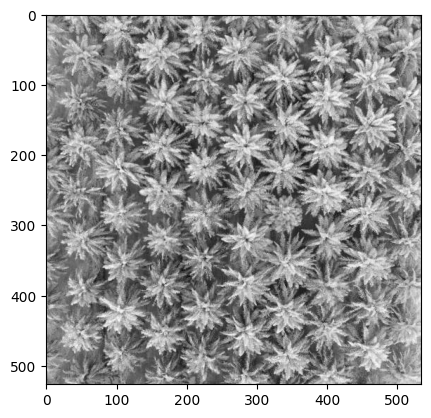

In [40]:
img_bgr = cv2.imread('palm_1.jpg')

img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
plt.imshow(img_gray, cmap='gray')
plt.title('Gray')
plt.show()

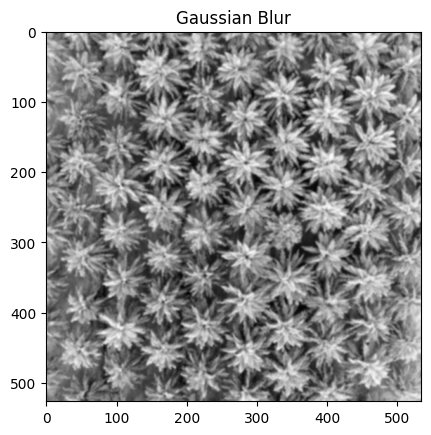

In [41]:
img_blurred = cv2.GaussianBlur(img_gray, (5, 5), 0)
plt.imshow(img_blurred, cmap='gray')
plt.title('Gaussian Blur')
plt.show()

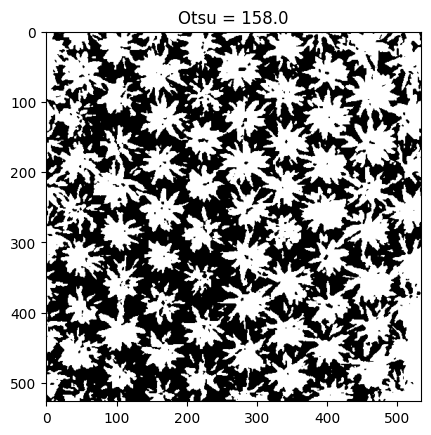

In [42]:
otsu_value, img_binary = cv2.threshold(
    img_blurred, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
plt.imshow(img_binary, cmap='gray')
plt.title(f'Otsu = {otsu_value:.1f}')
plt.show()

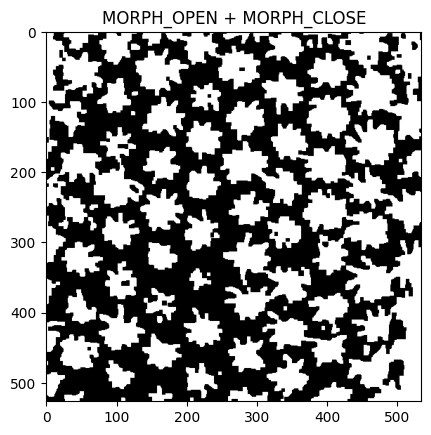

In [49]:
kernel = np.ones((3, 3), np.uint8)

img_binary = cv2.morphologyEx(img_binary, cv2.MORPH_OPEN,  kernel, iterations=2)
img_binary = cv2.morphologyEx(img_binary, cv2.MORPH_CLOSE, kernel, iterations=2)

plt.imshow(img_binary, cmap='gray')
plt.title('MORPH_OPEN + MORPH_CLOSE')
plt.show()

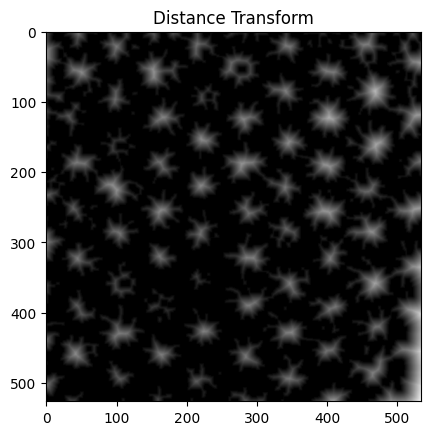

In [50]:
dist_map = cv2.distanceTransform(img_binary, cv2.DIST_L2, 5)
plt.imshow(dist_map, cmap='gray')
plt.title('Distance Transform')
plt.show()

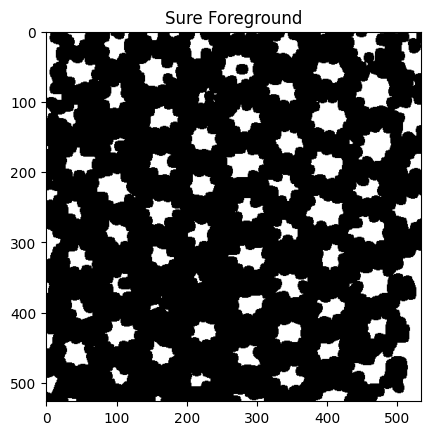

In [51]:
THRESHOLD_RATIO = 0.15
_, sure_foreground = cv2.threshold(
    dist_map, THRESHOLD_RATIO * dist_map.max(), 255, cv2.THRESH_BINARY
)
sure_foreground = sure_foreground.astype(np.uint8)

plt.imshow(sure_foreground, cmap='gray')
plt.title('Sure Foreground')
plt.show()

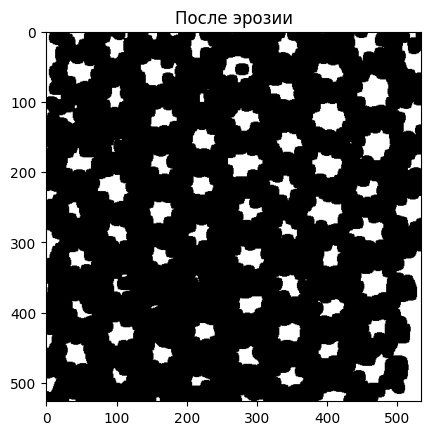

In [52]:
sure_foreground = cv2.erode(sure_foreground, kernel, iterations=1)

plt.imshow(sure_foreground, cmap='gray')
plt.title('After Erosion')
plt.show()

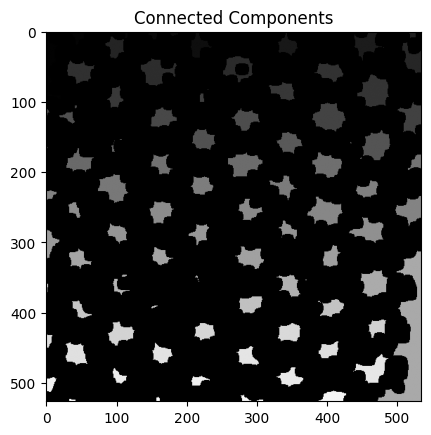

In [53]:
num_components, marker_labels = cv2.connectedComponents(
    sure_foreground, connectivity=4
)
plt.imshow(marker_labels, cmap='gray')
plt.title('Connected Components')
plt.show()

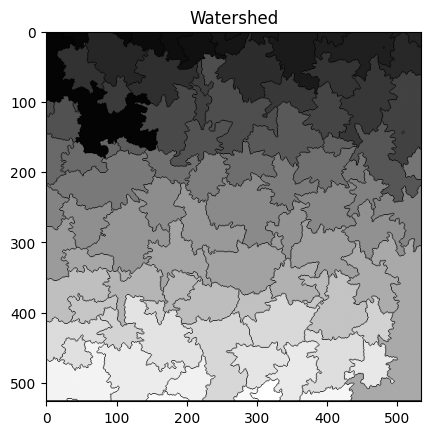

In [54]:
marker_labels = cv2.watershed(img_bgr, marker_labels)
plt.imshow(marker_labels, cmap='gray')
plt.title('Watershed')
plt.show()

In [55]:
labels_after = np.unique(marker_labels)
trees = labels_after[labels_after > 0]

print(f'Найдено пальм (примерно): {len(trees)}')
print(f'Всего меток: {len(labels_after)}')

Найдено пальм (примерно): 106
Всего меток: 107
